# Quantum Hackathon — Advanced Challenge Track
**Offline Qiskit / Aer | 220 points | 5 missions**

This notebook follows the QFF Pauli-observable exercise and requires **no IBM account, token, Runtime, or quantum hardware**. Complete each `TODO`, then call its grader. Each challenge is independent. Graders check computed behavior, not only variable names.

**Suggested timing:** CHSH 40 min; teleportation 50 min; Grover 50 min; noise 50 min; transpilation 60 min. Results from sampling vary slightly. Instructor solutions are distributed separately.

**Setup:** Install dependencies once while online, then run entirely offline.

In [19]:
# %pip install "qiskit>=1.2,<3" "qiskit-aer>=0.15,<1" numpy matplotlib

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp, state_fidelity, Operator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

SEED = 42
SHOTS = 4096
sim = AerSimulator(seed_simulator=SEED)
print('Offline Aer ready')

Offline Aer ready


In [21]:
# === LOCAL GRADERS (no IBM services) ===
def _report(name, parts):
    score=sum(points for _,passed,points in parts if passed)
    maximum=sum(points for _,_,points in parts)
    print(f'\n{name}: {score}/{maximum}')
    for label, passed, points in parts:
        print(('PASS' if passed else 'FAIL') + f' (+{points if passed else 0}/{points}) {label}')
    return score

def grade_chsh(bell, O00, O01, O10, O11):
    try:
        ops=[O00,O01,O10,O11]
        st=Statevector.from_instruction(bell)
        ideal=Statevector([1/np.sqrt(2),0,0,1/np.sqrt(2)])
        expected=[SparsePauliOp.from_list([('ZZ',1/np.sqrt(2)),('XZ',1/np.sqrt(2))]),
                  SparsePauliOp.from_list([('ZZ',1/np.sqrt(2)),('XZ',-1/np.sqrt(2))]),
                  SparsePauliOp.from_list([('ZX',1/np.sqrt(2)),('XX',1/np.sqrt(2))]),
                  SparsePauliOp.from_list([('ZX',1/np.sqrt(2)),('XX',-1/np.sqrt(2))])]
        correct_ops=all(np.allclose(Operator(a).data,Operator(b).data) for a,b in zip(ops,expected))
        s=sum(sign*float(np.real(st.expectation_value(op))) for sign,op in zip([1,1,1,-1],ops))
        print('S =',s)
        return _report('CHSH', [('Bell state',np.isclose(state_fidelity(st,ideal),1,atol=1e-6),10),('Correct four observables',correct_ops,20),('Violates classical bound',abs(s)>2+1e-5,10),('Tsirelson maximum',np.isclose(abs(s),2*np.sqrt(2),atol=1e-3),10)])
    except Exception as e: print('CHSH grader error:',e); return 0

def grade_teleportation(builder):
    try:
        tests=[(0.0,0.0),(np.pi,0.0),(np.pi/2,0.0),(1.12,0.81),(2.2,1.7)]
        scores=[]; structurally_valid=True
        from qiskit.quantum_info import partial_trace
        for theta,phi in tests:
            qc=builder(theta,phi)
            ops=qc.count_ops()
            structurally_valid &= (qc.num_qubits==3 and qc.num_clbits>=2 and ops.get('measure',0)>=2 and ops.get('if_else',0)>=2)
            test=qc.copy(); test.save_density_matrix()
            result=AerSimulator(method='density_matrix').run(test,shots=512,seed_simulator=SEED).result()
            rho=result.data(0)['density_matrix']
            reduced=partial_trace(rho,[0,1])
            target=QuantumCircuit(1);target.ry(theta,0);target.rz(phi,0)
            scores.append(float(state_fidelity(reduced,Statevector.from_instruction(target))))
        print('Teleportation fidelities:',np.round(scores,5))
        return _report('Teleportation',[('3 qubits, Bell measurement and corrections',structurally_valid,10),('All five states > 0.99 fidelity',all(x>.99 for x in scores),20)])
    except Exception as e: print('Teleportation grader error:',e);return 0

def grade_grover(builder):
    try:
        qc=builder();counts=AerSimulator(seed_simulator=SEED).run(qc,shots=SHOTS).result().get_counts()
        p=counts.get(MARKED,0)/SHOTS
        print('Counts:',counts,'success probability:',round(p,4))
        return _report('Grover',[('3 qubits, 3 measured bits',qc.num_qubits==3 and qc.num_clbits==3 and qc.count_ops().get('measure',0)==3,10),('Uses coherent oracle/diffuser gates',qc.count_ops().get('ccx',0)>=2 and qc.count_ops().get('h',0)>=3,10),('Success probability > 0.90',p>.90,20)])
    except Exception as e: print('Grover grader error:',e);return 0

def grade_noise(fn):
    try:
        ps=np.array(P_VALUES)
        ys=np.asarray(fn(P_VALUES),dtype=float)
        # Two-qubit depolarizing channel: rho -> (1-p)rho + p I/4
        expected=1-0.75*ps
        print('Observed:',ys,'Reference:',expected)
        return _report('Noise',[('Four finite fidelities',ys.shape==(4,) and np.isfinite(ys).all(),10),('Ideal p=0 fidelity 1',ys.shape==(4,) and abs(ys[0]-1)<.01,10),('Monotonically decreasing',ys.shape==(4,) and np.all(np.diff(ys)<0),10),('Matches two-qubit depolarizing model',ys.shape==(4,) and np.allclose(ys,expected,atol=.02),20)])
    except Exception as e: print('Noise grader error:',e);return 0

def grade_transpile(fn):
    try:
        result=fn(original)
        valid_basis=all(inst.operation.name in basis for inst in result.data)
        valid_edges=all((result.find_bit(inst.qubits[0]).index,result.find_bit(inst.qubits[1]).index) in coupling for inst in result.data if inst.operation.name=='cx')
        equivalent=Operator(result).equiv(Operator(original))
        print('Original ops:',original.count_ops(),'Optimized ops:',result.count_ops())
        return _report('Transpilation',[('Equivalent unitary',equivalent,20),('Allowed basis and connectivity',valid_basis and valid_edges,10),('Fewer CX gates',result.count_ops().get('cx',0)<original.count_ops().get('cx',0),10),('Fewer total gates',sum(result.count_ops().values())<sum(original.count_ops().values()),10)])
    except Exception as e: print('Transpilation grader error:',e);return 0

print('Five offline graders loaded')

Five offline graders loaded


## Mission 1 — CHSH Bell inequality (50 points)
Prepare a two-qubit Bell state and construct **four Pauli observables** for
\(A_0=Z, A_1=X\) on qubit 0 and \(B_0=(Z+X)/\sqrt2, B_1=(Z-X)/\sqrt2\) on qubit 1.

Use \(S=\langle A_0B_0
angle+\langle A_0B_1
angle+\langle A_1B_0
angle-\langle A_1B_1
angle\). Local classical bound: \(|S|\le2\); quantum maximum \(2\sqrt2\). **Qiskit Pauli labels are ordered q1 q0.**

In [22]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

s2 = 1/np.sqrt(2)
# Pauli labels are ordered q1 q0. A0=Z, A1=X on q0; B0=(Z+X)/sqrt2, B1=(Z-X)/sqrt2 on q1
O00 = SparsePauliOp.from_list([('ZZ', s2), ('XZ', s2)])    # A0 B0
O01 = SparsePauliOp.from_list([('ZZ', s2), ('XZ', -s2)])   # A0 B1
O10 = SparsePauliOp.from_list([('ZX', s2), ('XX', s2)])    # A1 B0
O11 = SparsePauliOp.from_list([('ZX', s2), ('XX', -s2)])   # A1 B1

S = sum(sign * np.real(Statevector.from_instruction(bell).expectation_value(op))
        for sign, op in zip([1, 1, 1, -1], [O00, O01, O10, O11]))
print('CHSH S:', S, ' 2*sqrt(2) =', 2*np.sqrt(2))

CHSH S: 2.8284271247461894  2*sqrt(2) = 2.8284271247461903


## Mission 2 — Quantum teleportation (30 points)
Teleport an *unknown* single-qubit state from q0 to q2 using an entangled pair q1–q2, two measurements, and conditional corrections. Build `make_teleportation(theta, phi)` returning a 3-qubit circuit with two classical bits. Prepare the input as `ry(theta, 0); rz(phi, 0)`. **Do not directly prepare the target state on q2.** Use classical feed-forward (`if_test`) to correct q2. The grader checks several different input states using a local density-matrix simulator.

In [23]:
def make_teleportation(theta, phi):
    qc = QuantumCircuit(3, 2)
    qc.ry(theta, 0)
    qc.rz(phi, 0)
    # Bell pair on q1, q2
    qc.h(1)
    qc.cx(1, 2)
    # Bell-basis measurement of q0, q1
    qc.cx(0, 1)
    qc.h(0)
    qc.measure(0, 0)
    qc.measure(1, 1)
    # feed-forward corrections on q2
    with qc.if_test((qc.clbits[1], 1)):
        qc.x(2)
    with qc.if_test((qc.clbits[0], 1)):
        qc.z(2)
    return qc

grade_teleportation(make_teleportation)

Teleportation fidelities: [1. 1. 1. 1. 1.]

Teleportation: 30/30
PASS (+10/10) 3 qubits, Bell measurement and corrections
PASS (+20/20) All five states > 0.99 fidelity


30

## Mission 3 — Grover search (40 points)
Find the marked bitstring `101` among 8 possibilities. Create `make_grover()` returning a **3-qubit circuit with measurements**. Implement the phase oracle and diffuser yourself; no `initialize` with the solution state and no classical lookup. Use **two Grover iterations**. Qiskit count strings are displayed q2 q1 q0.

In [24]:
MARKED = '101'

def phase_oracle_101(qc):
    # flip phase of |101> (q2 q1 q0 = 1 0 1): X on q1 turns it into |111>, then CCZ
    qc.x(1)
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1)

def diffuser(qc):
    qc.h([0, 1, 2])
    qc.x([0, 1, 2])
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x([0, 1, 2])
    qc.h([0, 1, 2])

def make_grover():
    qc = QuantumCircuit(3, 3)
    qc.h([0, 1, 2])
    for _ in range(2):
        phase_oracle_101(qc)
        diffuser(qc)
    qc.measure([0,1,2], [0,1,2])
    return qc

grade_grover(make_grover)

Counts: {'101': 3889, '001': 25, '010': 26, '110': 41, '011': 30, '000': 33, '111': 31, '100': 21} success probability: 0.9495

Grover: 40/40
PASS (+10/10) 3 qubits, 3 measured bits
PASS (+10/10) Uses coherent oracle/diffuser gates
PASS (+20/20) Success probability > 0.90


40

## Mission 4 — Noisy Bell pair (50 points)
Use `AerSimulator` and `NoiseModel` to apply **two-qubit depolarizing error** to `cx` for strengths \(p=0,0.05,0.15,0.3\). Measure the probability of observing `00` or `11` after preparing a Bell state. Return the vector of *estimated Bell-state fidelities* using the density-matrix save instruction (not only Z-basis counts; Z correlations alone are insufficient to establish Bell fidelity).

Write `bell_fidelities(p_values)` returning four numbers. Plot fidelity vs noise strength. The local grader compares to a known reference and checks monotonicity.

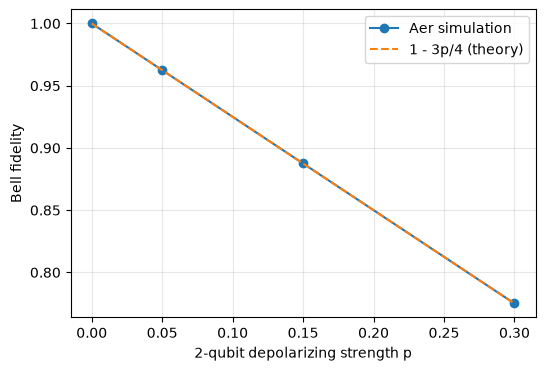

In [25]:
P_VALUES = [0.0, 0.05, 0.15, 0.30]

def bell_fidelities(p_values=P_VALUES):
    ideal = Statevector([1/np.sqrt(2), 0, 0, 1/np.sqrt(2)])
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    qc.save_density_matrix()
    fids = []
    for p in p_values:
        nm = NoiseModel()
        if p > 0:
            nm.add_all_qubit_quantum_error(depolarizing_error(p, 2), ['cx'])
        backend = AerSimulator(method='density_matrix', noise_model=nm, seed_simulator=SEED)
        tqc = transpile(qc, backend, optimization_level=0)
        rho = backend.run(tqc).result().data(0)['density_matrix']
        fids.append(float(state_fidelity(rho, ideal)))
    return np.array(fids)

fids = bell_fidelities(P_VALUES)
plt.figure(figsize=(6,4))
plt.plot(P_VALUES, fids, 'o-', label='Aer simulation')
plt.plot(P_VALUES, 1 - 0.75*np.array(P_VALUES), '--', label='1 - 3p/4 (theory)')
plt.xlabel('2-qubit depolarizing strength p'); plt.ylabel('Bell fidelity')
plt.grid(alpha=.3); plt.legend(); plt.show()

## Mission 5 — Transpilation / optimization (50 points)
Optimize a deliberately redundant **3-qubit unitary circuit** for a *linear coupling map* `[(0,1),(1,0),(1,2),(2,1)]` with basis `['rz','sx','x','cx']`. Return a compiled `QuantumCircuit` from `optimize_circuit(original)`.

The grader checks **unitary equivalence up to global phase**, valid basis/coupling, fewer `cx` gates, and lower total gate count. Do not use measurements or hard-code a different target unitary.

In [26]:
coupling = [(0,1),(1,0),(1,2),(2,1)]
basis = ['rz','sx','x','cx']
original = QuantumCircuit(3)
original.h(0)
original.cx(0,1)
original.cx(0,1)  # cancellation opportunity
original.cx(1,2)
original.rz(0.3, 2)
original.rz(-0.3, 2)
original.cx(1,2)  # cancellation opportunity
original.x(0)
original.x(0)
original.h(0)
original.cx(0,1)
original.cx(0,1)

def optimize_circuit(original):
    from qiskit.transpiler import CouplingMap
    # initial_layout fixed to identity so the unitary is directly comparable
    return transpile(original, coupling_map=CouplingMap(coupling), basis_gates=basis,
                     initial_layout=[0, 1, 2], optimization_level=3, seed_transpiler=SEED)

grade_transpile(optimize_circuit)

Original ops: OrderedDict([('cx', 6), ('h', 2), ('rz', 2), ('x', 2)]) Optimized ops: OrderedDict()

Transpilation: 50/50
PASS (+20/20) Equivalent unitary
PASS (+10/10) Allowed basis and connectivity
PASS (+10/10) Fewer CX gates
PASS (+10/10) Fewer total gates


50

## Submit your challenges
Uncomment each grader call **after** finishing its mission. Each grader reports points immediately. The maximum total is **220 points**. Local graders are learning aids, not tamper-resistant competition infrastructure.

In [27]:
total = grade_chsh(bell, O00, O01, O10, O11) + grade_teleportation(make_teleportation) + grade_grover(make_grover) + grade_noise(bell_fidelities) + grade_transpile(optimize_circuit)
print('\nTOTAL:', total, '/ 220')

S = 2.8284271247461894

CHSH: 50/50
PASS (+10/10) Bell state
PASS (+20/20) Correct four observables
PASS (+10/10) Violates classical bound
PASS (+10/10) Tsirelson maximum
Teleportation fidelities: [1. 1. 1. 1. 1.]

Teleportation: 30/30
PASS (+10/10) 3 qubits, Bell measurement and corrections
PASS (+20/20) All five states > 0.99 fidelity
Counts: {'101': 3889, '001': 25, '010': 26, '110': 41, '011': 30, '000': 33, '111': 31, '100': 21} success probability: 0.9495

Grover: 40/40
PASS (+10/10) 3 qubits, 3 measured bits
PASS (+10/10) Uses coherent oracle/diffuser gates
PASS (+20/20) Success probability > 0.90
Observed: [1.     0.9625 0.8875 0.775 ] Reference: [1.     0.9625 0.8875 0.775 ]

Noise: 50/50
PASS (+10/10) Four finite fidelities
PASS (+10/10) Ideal p=0 fidelity 1
PASS (+10/10) Monotonically decreasing
PASS (+20/20) Matches two-qubit depolarizing model
Original ops: OrderedDict([('cx', 6), ('h', 2), ('rz', 2), ('x', 2)]) Optimized ops: OrderedDict()

Transpilation: 50/50
PASS (+20/